# V2 kayitli sonuclar — salt okuma; completed fiziksel kabul degildir.


Grup: completed | completed fiziksel kabul degildir


,experiment_id,scenario_id,state,controls,calculation,k,MC_standard_error,duration_s,fields_npz,summary_json,physical_acceptance,statistical_convergence
0,V2-HALTON_02-0001,679039b2f441f98ae947bc9c230f8cc45f371f6ce8f6e3...,completed,{'u235_enrichment_wt_percent': 2.2318403532697...,"{'particles_per_generation': 80000, 'batches':...",1.169186,0.000180,993.124954,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
1,V2-HALTON_02-0002,10a97412392d5c9eef444892403ccf1ea6bed75f114d77...,completed,{'u235_enrichment_wt_percent': 1.8568403532697...,"{'particles_per_generation': 80000, 'batches':...",1.092523,0.000160,1026.134046,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
2,V2-HALTON_02-0003,cbdfa2d0442a1eb70103d68d60312ac3d95f110b266d10...,completed,{'u235_enrichment_wt_percent': 2.6068403532697...,"{'particles_per_generation': 80000, 'batches':...",1.187687,0.000178,966.150214,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
3,V2-HALTON_02-0004,fb52378ddd16772231e2afb2cf53a44271a4ac1e967a97...,completed,{'u235_enrichment_wt_percent': 1.6693403532697...,"{'particles_per_generation': 80000, 'batches':...",1.022687,0.000158,1033.100101,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
4,V2-HALTON_02-0005,ff024c74f11bdfa0781ff746576e7a563f7039857c6b74...,completed,{'u235_enrichment_wt_percent': 2.4193403532697...,"{'particles_per_generation': 80000, 'batches':...",1.135380,0.000182,1010.241452,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
5,V2-HALTON_02-0006,e0acc66ba003861d1115aff2d44843cb6e4efbb986d4da...,completed,{'u235_enrichment_wt_percent': 2.0443403532697...,"{'particles_per_generation': 80000, 'batches':...",1.235087,0.000195,1040.304854,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
6,V2-HALTON_02-0007,42aa9a930a92e5fb89fe7694a5d8bb911b4e2c24d69975...,completed,{'u235_enrichment_wt_percent': 2.7943403532697...,"{'particles_per_generation': 80000, 'batches':...",1.303225,0.000183,982.707573,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
7,V2-HALTON_02-0008,339adb47b899ec137a7a927e04f0aff5b039a6e2187437...,completed,{'u235_enrichment_wt_percent': 2.9349653532697...,"{'particles_per_generation': 80000, 'batches':...",1.294445,0.000192,977.294140,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
8,V2-HALTON_02-0009,be1f628b2b0fa65ebc27ecce9ca234ebfd993009841673...,completed,{'u235_enrichment_wt_percent': 2.1849653532697...,"{'particles_per_generation': 80000, 'batches':...",1.189070,0.000173,1014.093576,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
9,V2-HALTON_02-0010,eb6bc6e027a5f42a6bae213d292a50a8d0d20346e0d01e...,completed,{'u235_enrichment_wt_percent': 1.8099653532697...,"{'particles_per_generation': 80000, 'batches':...",1.102662,0.000183,1034.977301,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required


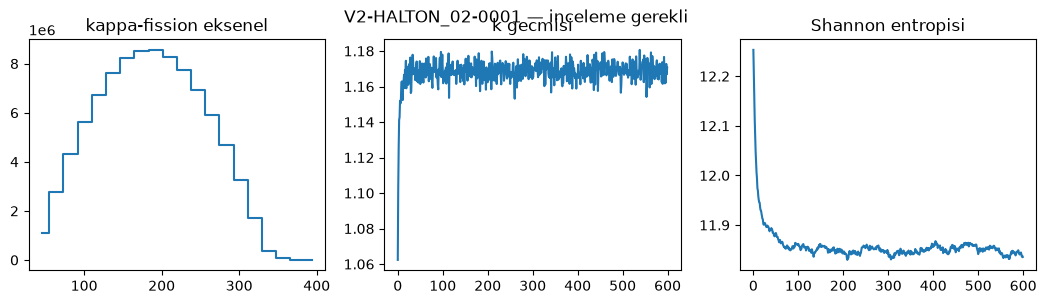

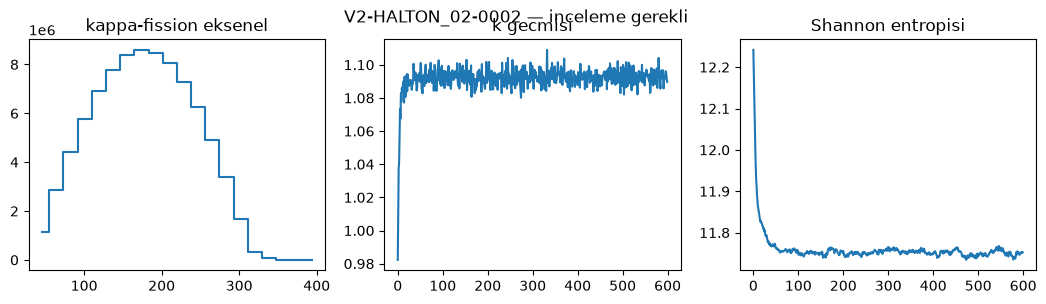

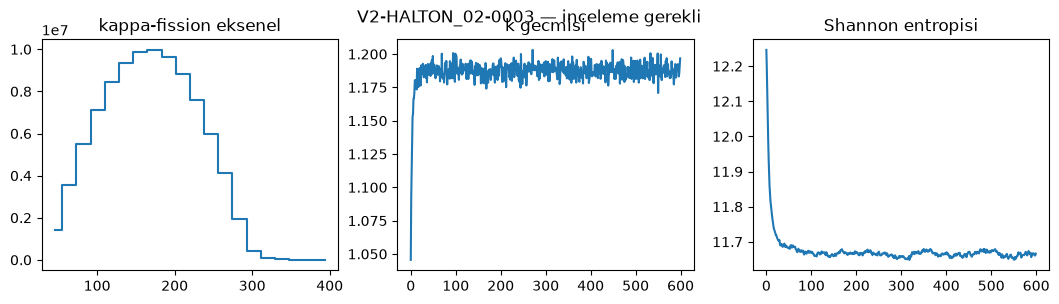

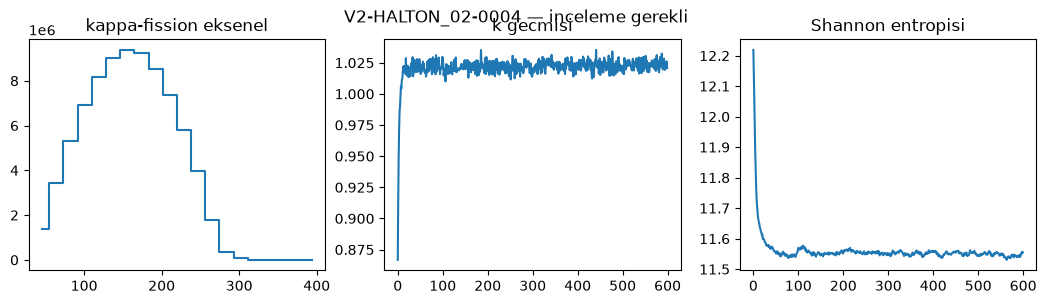

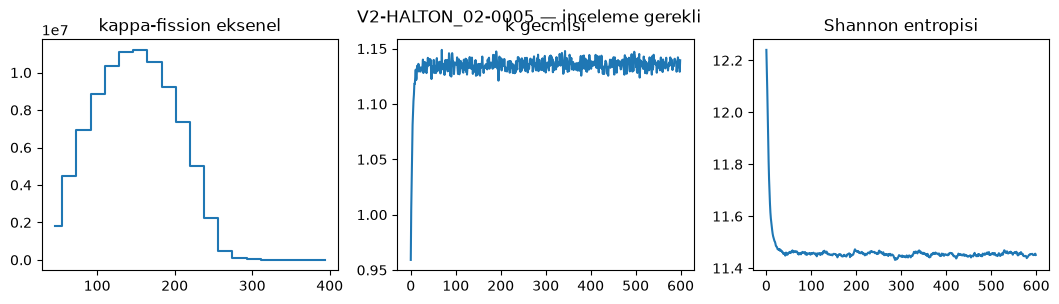

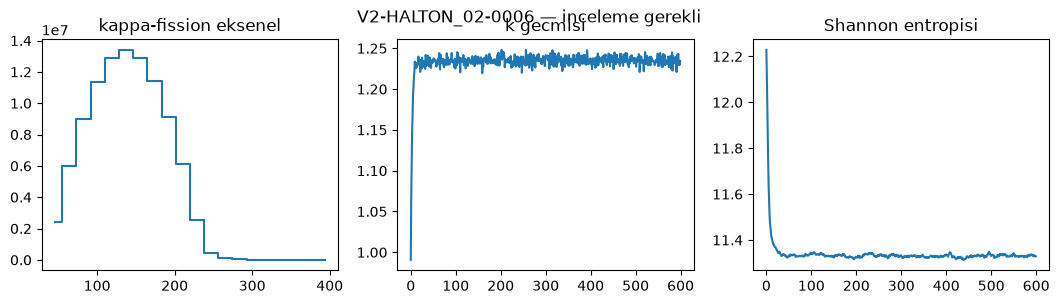

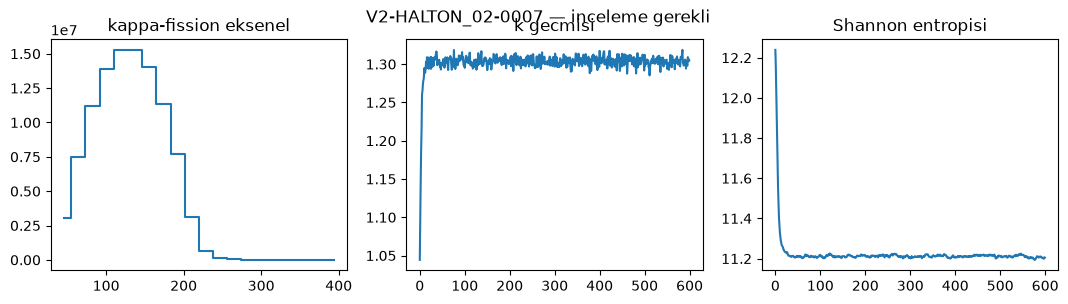

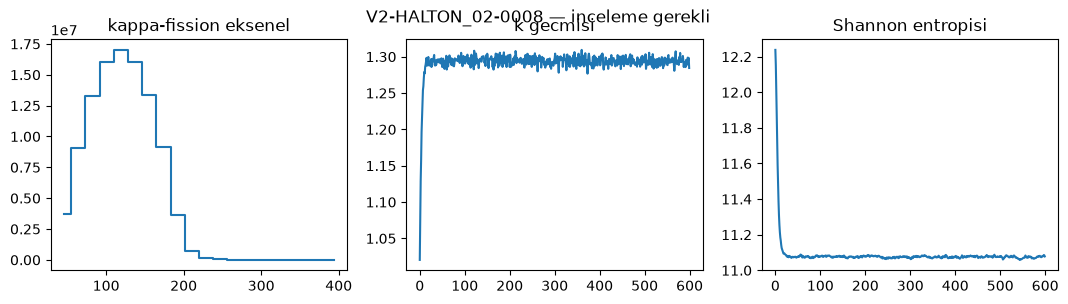

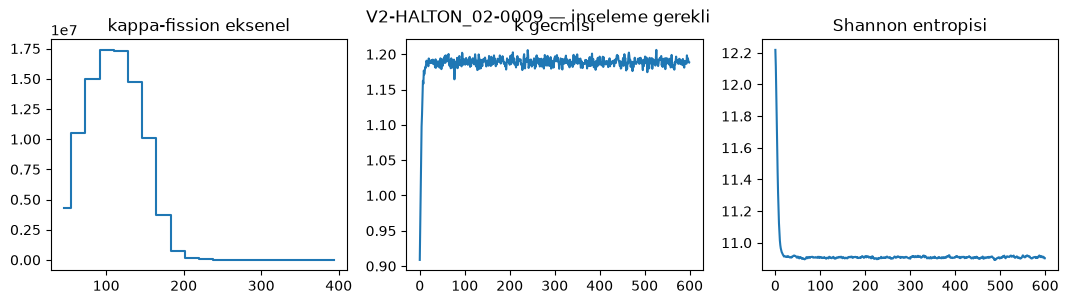

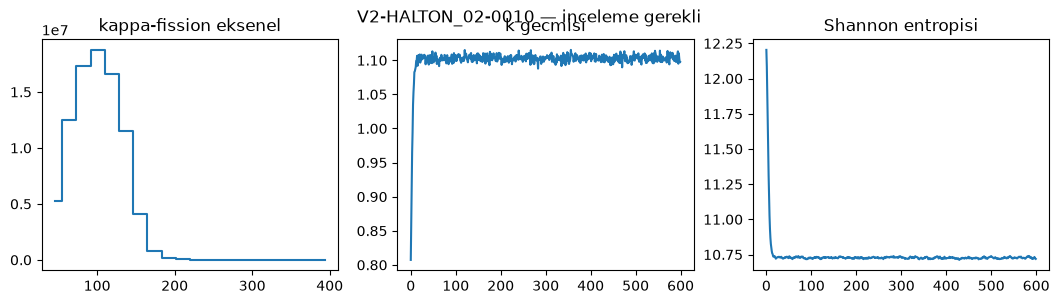

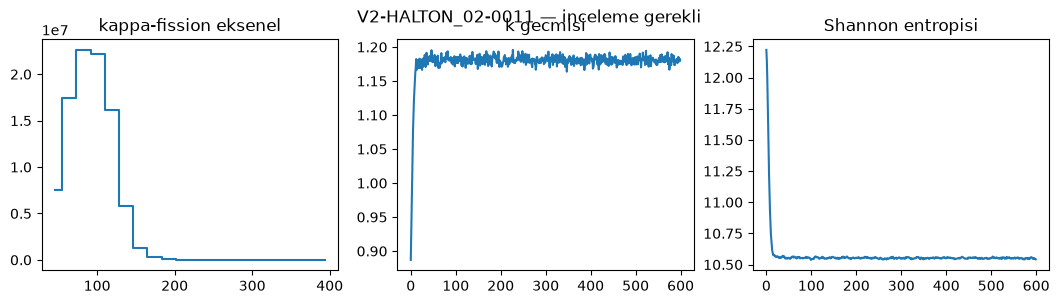

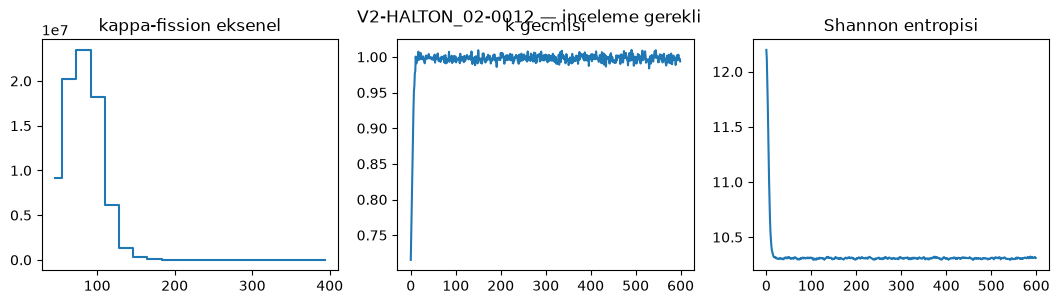

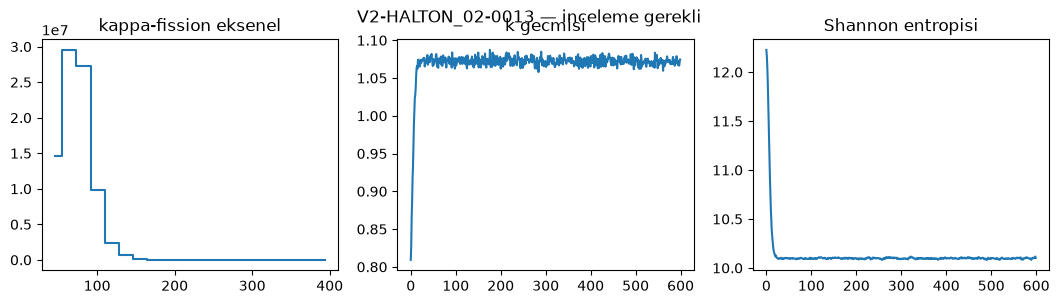

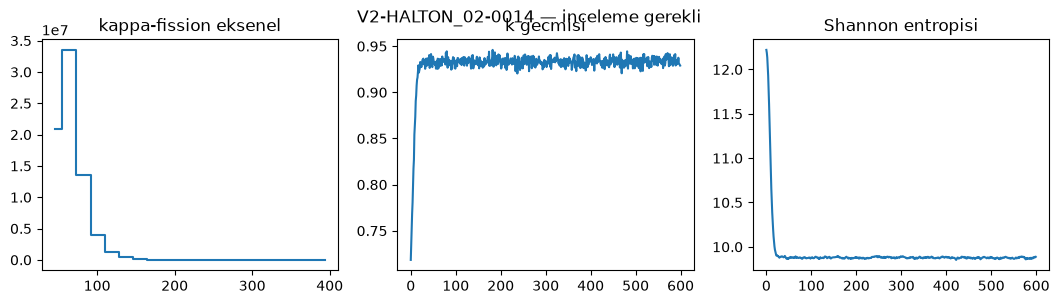

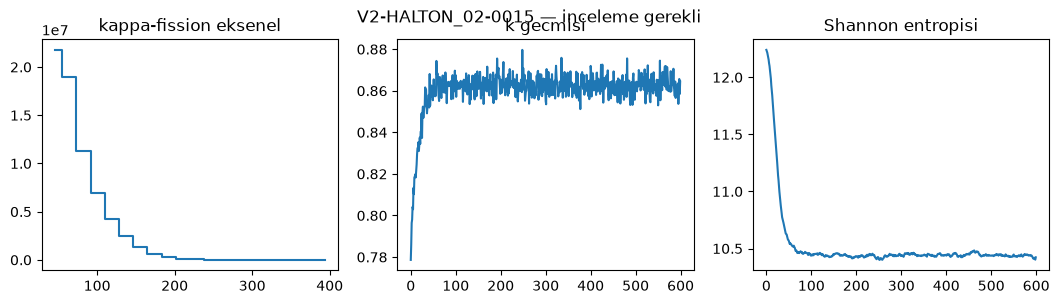

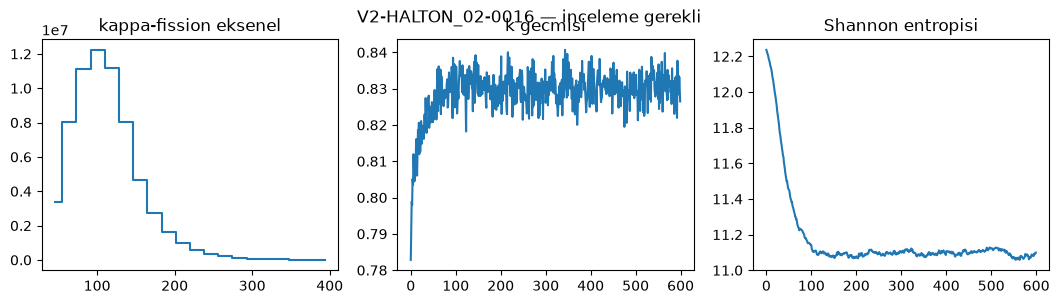

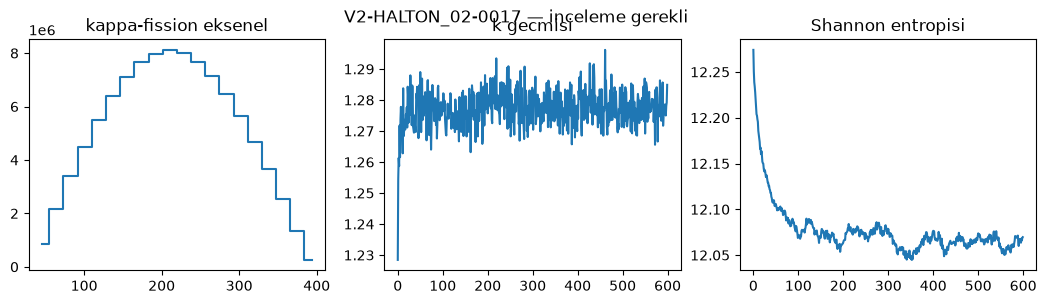

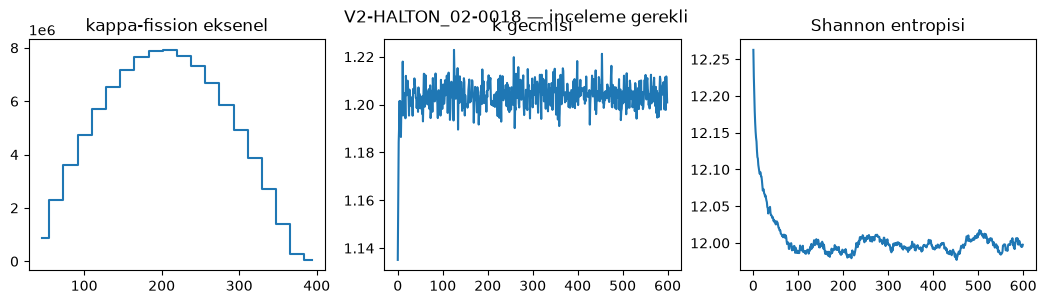

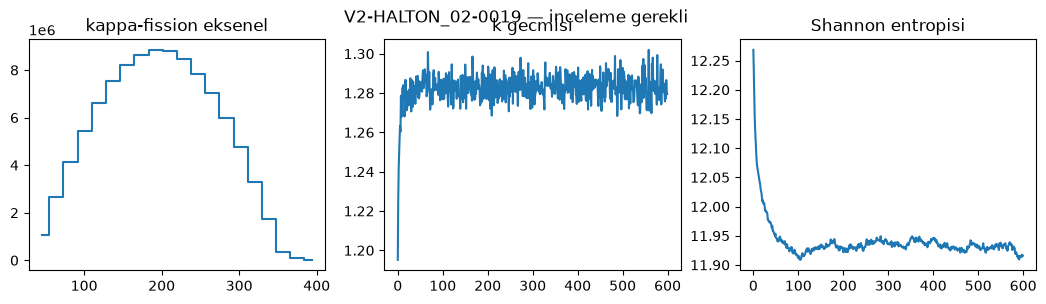

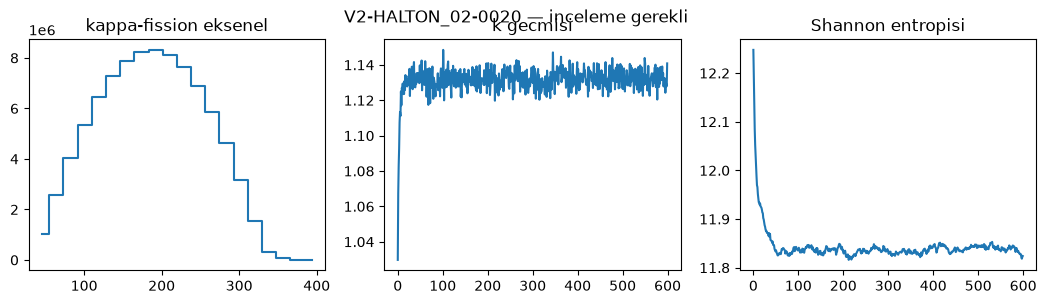

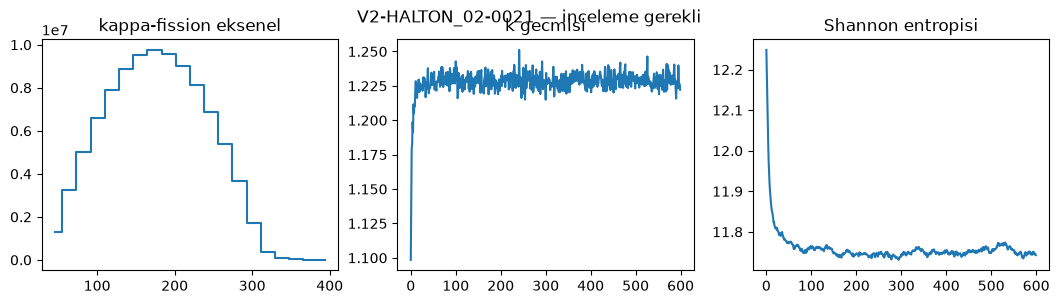

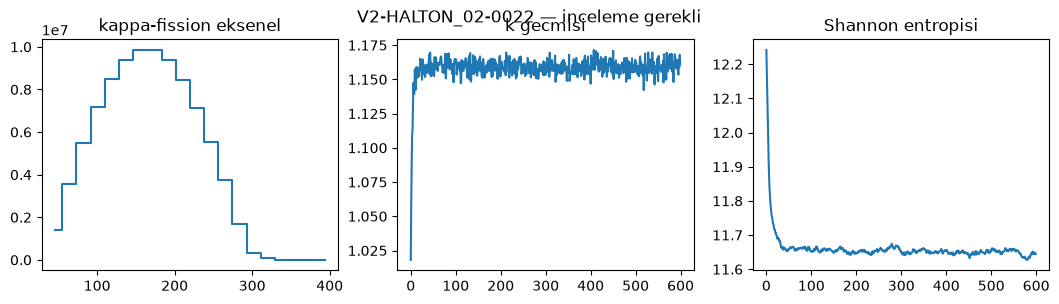

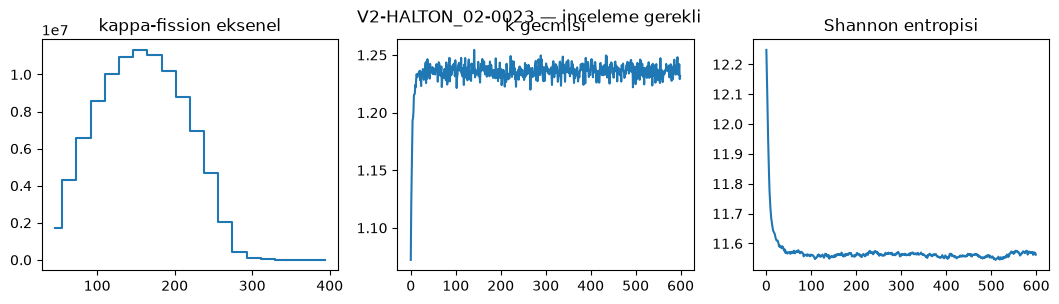

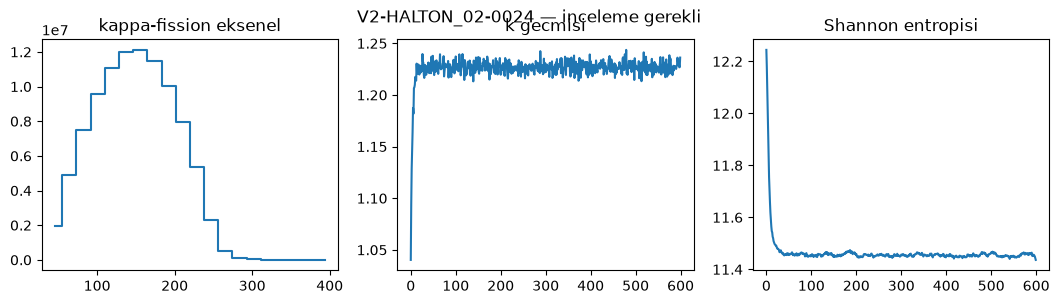

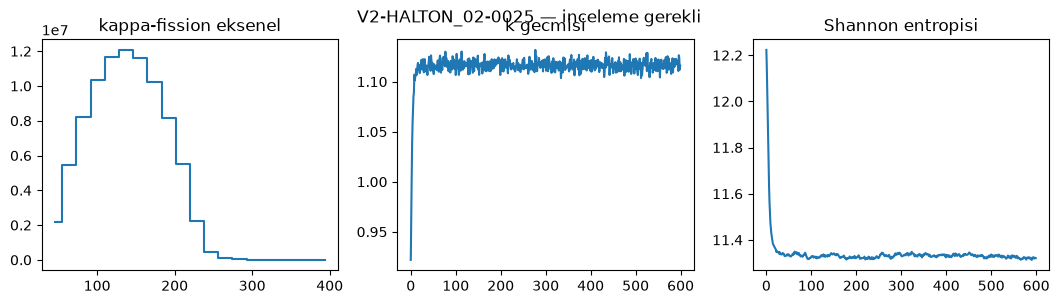

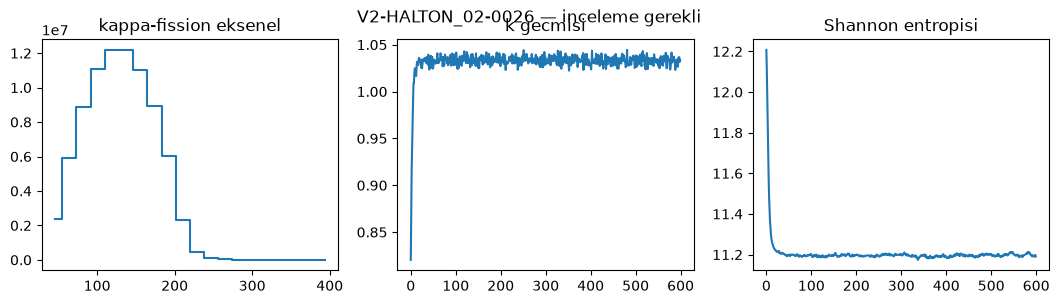

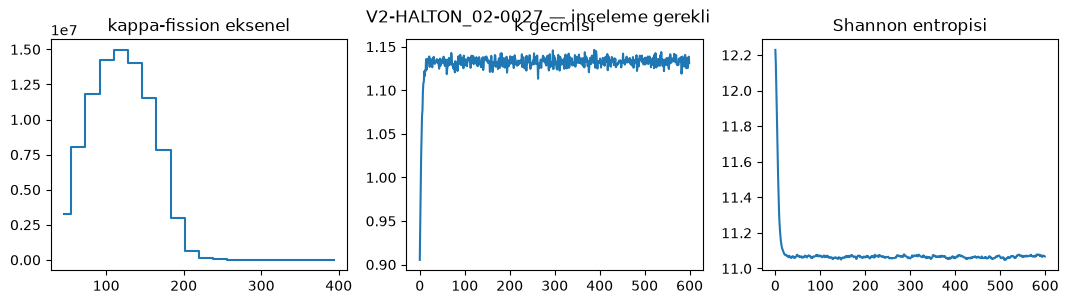

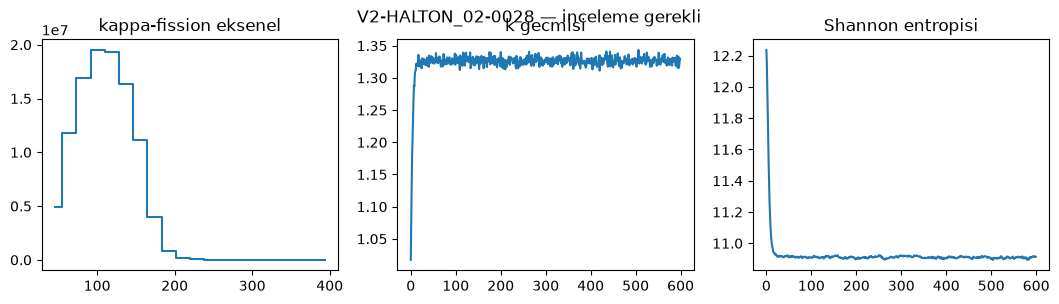

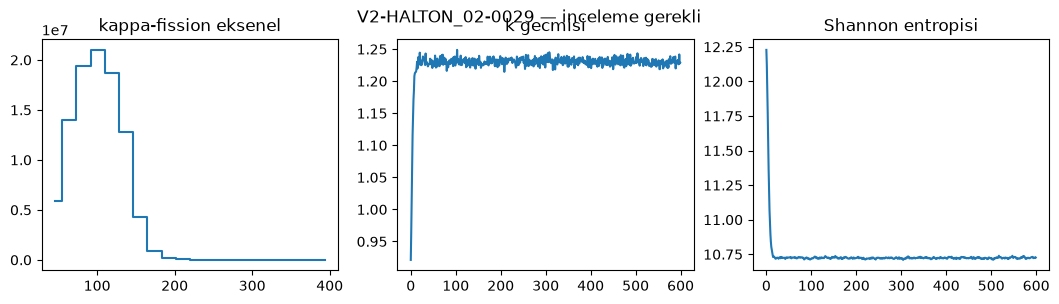

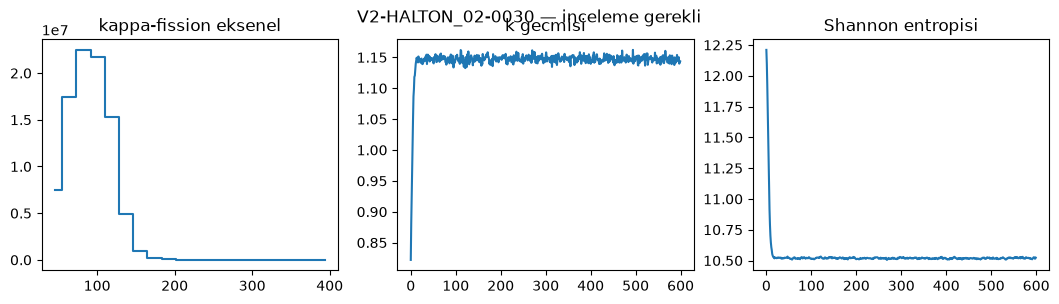

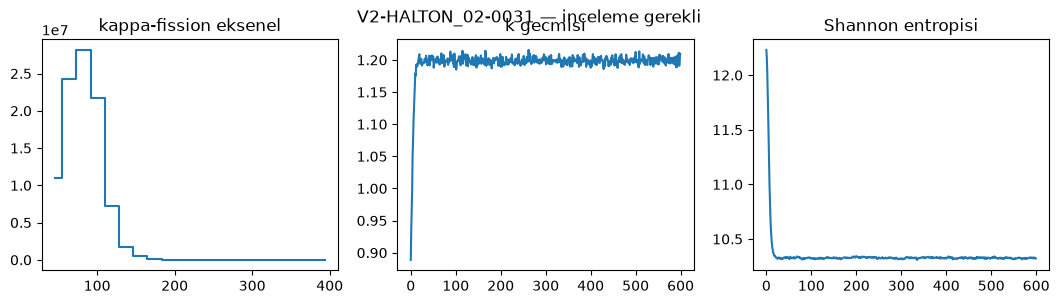

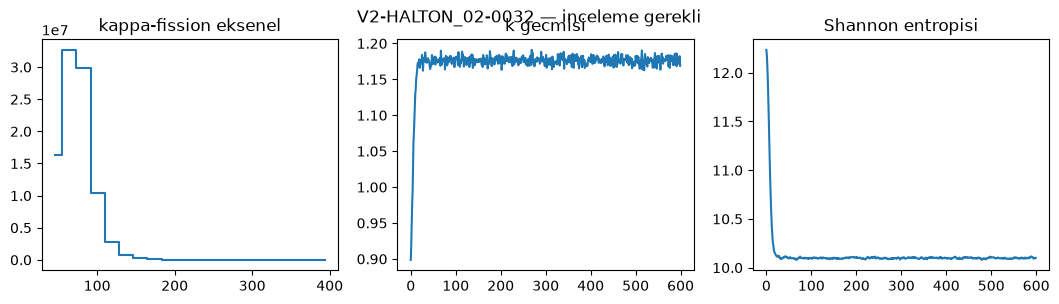

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, sys
PACKAGE = Path.cwd().resolve()
PROJECT = next(p for p in (PACKAGE, *PACKAGE.parents) if (p / "src/reactor_pipeline/v2_students.py").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from reactor_pipeline import v2_student_runner, v2_students
assert PACKAGE.name == "v2_halton_02_beavrs_v2_pilot_scope_v1"
info = v2_students.verify_package(PACKAGE, require_approval=False)
saved = v2_student_runner.saved_results(PACKAGE)
print("Grup:", saved["group"]["state"], "| completed fiziksel kabul degildir")
rows = []
for case in saved["cases"]:
    summary = case["summary"] or {}
    k = summary.get("k_effective", {})
    manifest_case = next(x for x in v2_students._read(PACKAGE / "manifest.json")["experiments"]
                         if x["experiment_id"] == case["experiment_id"])
    rows.append({"experiment_id": case["experiment_id"],
                 "scenario_id": case["scenario_id"], "state": case["state"],
                 "controls": manifest_case["controls"], "calculation": manifest_case["calculation"],
                 "k": k.get("mean"), "MC_standard_error": k.get("mc_standard_error"),
                 "duration_s": summary.get("duration", {}).get("value"),
                 "fields_npz": str(Path(case["attempt"]) / "fields.npz") if case["attempt"] else None,
                 "summary_json": str(Path(case["attempt"]) / "summary.json") if case["attempt"] else None,
                 "physical_acceptance": case["physical_acceptance"],
                 "statistical_convergence": case["statistical_convergence"]})
display(pd.DataFrame(rows))
for case in saved["cases"]:
    if case["state"] != "completed":
        continue
    with np.load(Path(case["attempt"]) / "fields.npz", allow_pickle=False) as fields:
        z = fields["z_edges_cm"]
        axial = fields["kappa_fission_mean"].sum(axis=(1, 2))
        k_history = fields["k_generation"].copy()
        entropy = fields["shannon_entropy"].copy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].step((z[:-1]+z[1:])/2, axial, where="mid")
    axes[0].set_title("kappa-fission eksenel")
    axes[1].plot(k_history); axes[1].set_title("k gecmisi")
    axes[2].plot(entropy); axes[2].set_title("Shannon entropisi")
    fig.suptitle(case["experiment_id"] + " — inceleme gerekli")
    display(fig)
    plt.close(fig)


## Teslim — hesap başlatmaz
Tamamlanan koşular için WSL terminalinde: `python scripts/v2_transfer.py export student_packages/v2_halton128_v1/halton_02/v2_halton_02_beavrs_v2_pilot_scope_v1 deliveries/v2_halton_02_beavrs_v2_pilot_scope_v1.zip`. Durum `completed` olmadan teslim tam sayılmaz; varsayılan ZIP statepoint içermez.
